Purpose: Exploratory analysis of multivariate sensor structure and coordinated transitions. PCA is used only to visualize the joint sensor behaviour;

In [1]:
import pandas as pd
import numpy as np

# Load original dataset
df = pd.read_csv("../data/Data.csv")

# Sensor columns
sensor_cols = [
    "Cyclone_Inlet_Gas_Temp",
    "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft",
    "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp",
    "Cyclone_Inlet_Draft"
]

# Parse timestamp using the two formats found during EDA
slash_mask = df["time"].astype(str).str.contains("/", regex=False)

df["time_dt"] = pd.NaT

df.loc[~slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[~slash_mask, "time"],
    format="%m-%d-%Y %H:%M",
    errors="coerce"
)

df.loc[slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[slash_mask, "time"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Convert sensors to numeric
sensor_numeric = df[sensor_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Keep only rows where all 6 sensors have numerical readings
valid_mask = sensor_numeric.notna().all(axis=1)

model_df = pd.concat(
    [
        df.loc[valid_mask, "time_dt"],
        sensor_numeric.loc[valid_mask]
    ],
    axis=1
).reset_index(drop=True)

print("Original data:", df.shape)
print("Modeling data:", model_df.shape)
print("Missing sensor values:", model_df[sensor_cols].isna().sum().sum())

Original data: (377719, 8)
Modeling data: (376124, 7)
Missing sensor values: 0


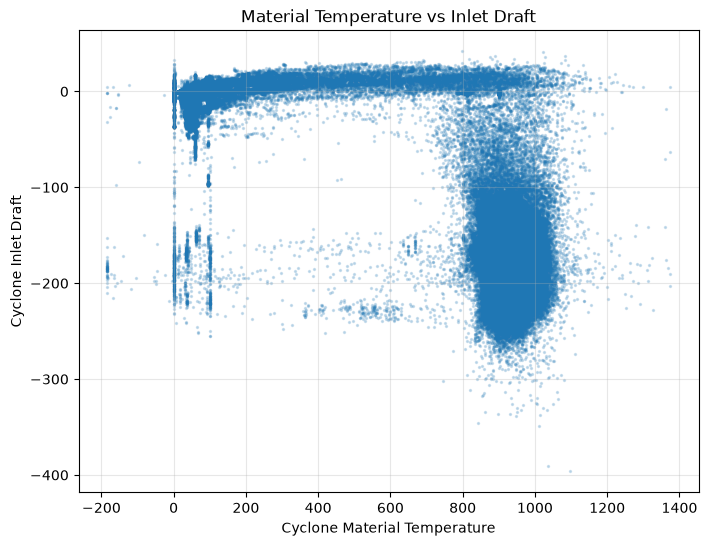

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    model_df["Cyclone_Material_Temp"],
    model_df["Cyclone_Inlet_Draft"],
    s=2,
    alpha=0.2
)

plt.xlabel("Cyclone Material Temperature")
plt.ylabel("Cyclone Inlet Draft")
plt.title("Material Temperature vs Inlet Draft")
plt.grid(alpha=0.3)

plt.show()

Explained variance ratio: [0.93774293 0.04531948]
Total explained variance: 0.9830624097228841


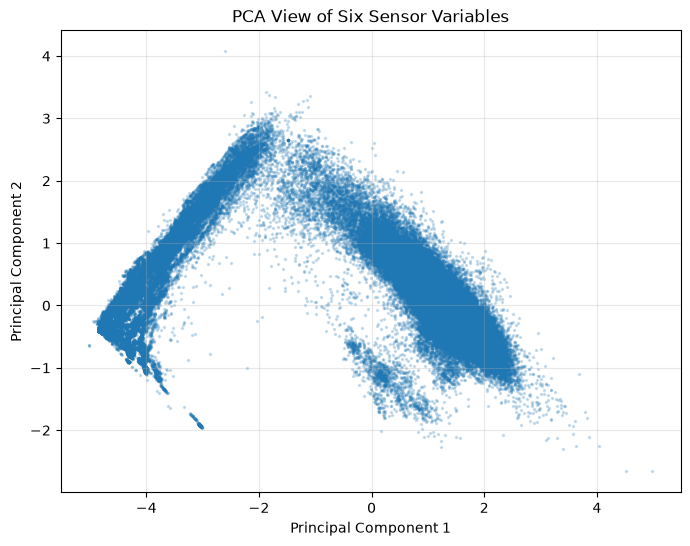

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X = model_df[sensor_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=2,
    alpha=0.2
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA View of Six Sensor Variables")
plt.grid(alpha=0.3)

plt.show()

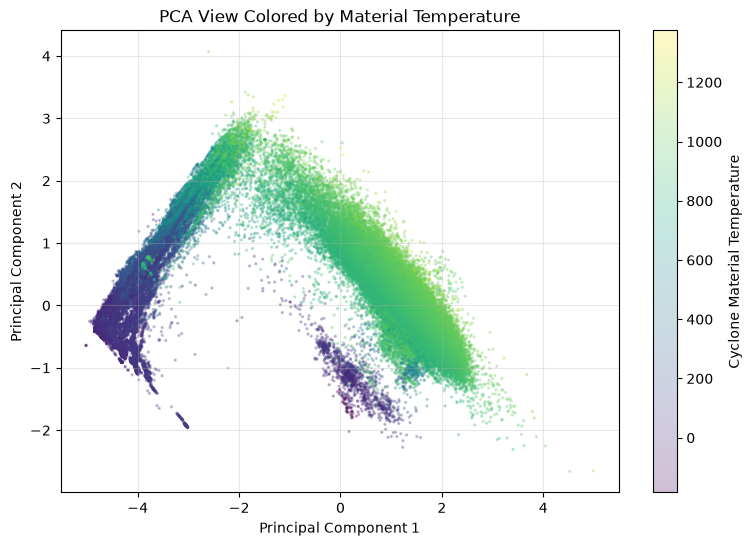

In [4]:
import matplotlib.pyplot as plt

material_temp = model_df["Cyclone_Material_Temp"]

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=material_temp,
    s=2,
    alpha=0.25
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA View Colored by Material Temperature")

plt.colorbar(scatter, label="Cyclone Material Temperature")

plt.grid(alpha=0.3)
plt.show()

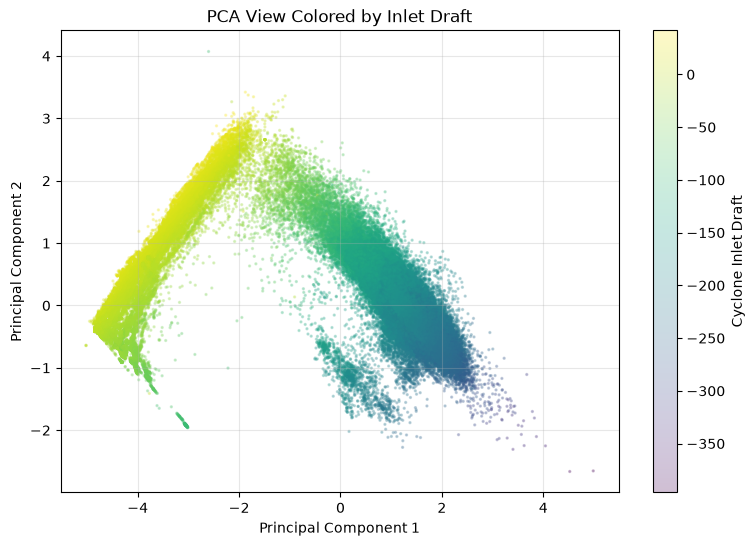

In [5]:
inlet_draft = model_df["Cyclone_Inlet_Draft"]

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=inlet_draft,
    s=2,
    alpha=0.25
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA View Colored by Inlet Draft")

plt.colorbar(scatter, label="Cyclone Inlet Draft")

plt.grid(alpha=0.3)
plt.show()

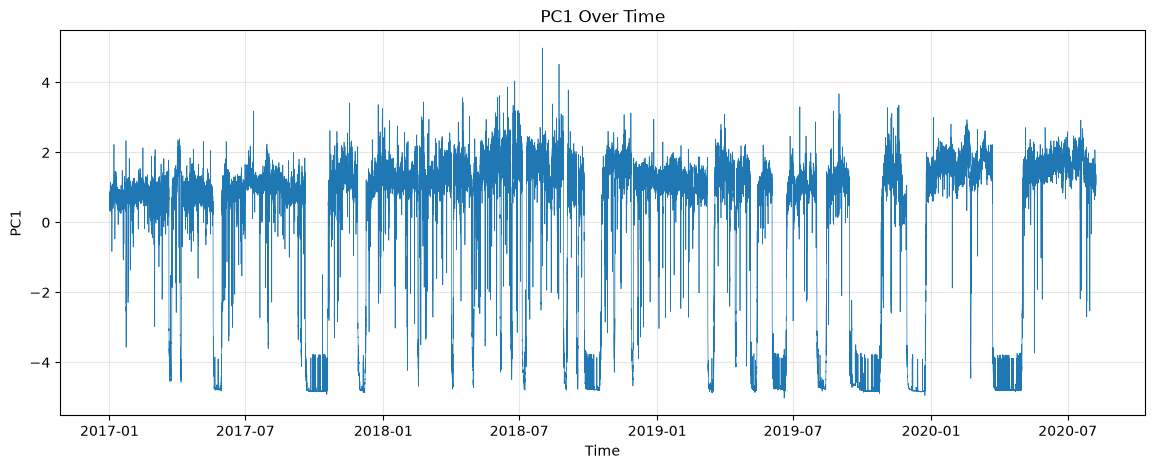

In [6]:
# Add PCA components to our modeling dataframe
model_df["PC1"] = X_pca[:, 0]
model_df["PC2"] = X_pca[:, 1]

# Sort by time
model_df = model_df.sort_values("time_dt").reset_index(drop=True)

plt.figure(figsize=(14, 5))

plt.plot(
    model_df["time_dt"],
    model_df["PC1"],
    linewidth=0.5
)

plt.xlabel("Time")
plt.ylabel("PC1")
plt.title("PC1 Over Time")
plt.grid(alpha=0.3)

plt.show()

In [7]:
# Calculate the change in PC1 between consecutive observations
model_df["PC1_change"] = model_df["PC1"].diff()

# Find the largest downward movements
largest_drops = (
    model_df[["time_dt", "PC1", "PC1_change"]]
    .sort_values("PC1_change")
    .head(10)
)

print(largest_drops)

                   time_dt       PC1  PC1_change
159781 2018-07-15 01:45:00 -2.143257   -4.380469
177702 2018-09-15 08:35:00 -2.601877   -4.137799
171011 2018-08-23 02:20:00  0.411324   -4.110667
164657 2018-08-01 00:10:00  1.009791   -3.975628
297950 2019-11-08 16:30:00 -2.014082   -3.767176
198604 2018-11-27 05:40:00 -2.117441   -3.746401
370383 2020-07-18 13:05:00 -0.726981   -3.649392
301381 2019-11-20 16:10:00 -2.114605   -3.563271
217291 2019-02-01 03:05:00 -1.896147   -3.554412
26918  2017-04-04 17:15:00 -1.730909   -3.552352


In [8]:
# Check the time gap associated with the largest PC1 drops

largest_drops = largest_drops.copy()

largest_drops["previous_time"] = (
    model_df["time_dt"]
    .shift(1)
    .loc[largest_drops.index]
)

largest_drops["time_gap"] = (
    largest_drops["time_dt"] - largest_drops["previous_time"]
)

print(
    largest_drops[
        ["previous_time", "time_dt", "time_gap", "PC1", "PC1_change"]
    ]
)

             previous_time             time_dt        time_gap       PC1  \
159781 2018-07-15 01:40:00 2018-07-15 01:45:00 0 days 00:05:00 -2.143257   
177702 2018-09-15 08:30:00 2018-09-15 08:35:00 0 days 00:05:00 -2.601877   
171011 2018-08-23 02:15:00 2018-08-23 02:20:00 0 days 00:05:00  0.411324   
164657 2018-08-01 00:05:00 2018-08-01 00:10:00 0 days 00:05:00  1.009791   
297950 2019-11-08 16:25:00 2019-11-08 16:30:00 0 days 00:05:00 -2.014082   
198604 2018-11-27 05:35:00 2018-11-27 05:40:00 0 days 00:05:00 -2.117441   
370383 2020-07-18 13:00:00 2020-07-18 13:05:00 0 days 00:05:00 -0.726981   
301381 2019-11-20 16:05:00 2019-11-20 16:10:00 0 days 00:05:00 -2.114605   
217291 2019-02-01 03:00:00 2019-02-01 03:05:00 0 days 00:05:00 -1.896147   
26918  2017-04-04 17:10:00 2017-04-04 17:15:00 0 days 00:05:00 -1.730909   

        PC1_change  
159781   -4.380469  
177702   -4.137799  
171011   -4.110667  
164657   -3.975628  
297950   -3.767176  
198604   -3.746401  
370383   -3.6493

In [9]:
candidate_time = pd.Timestamp("2018-07-15 01:45:00")

window = model_df[
    (model_df["time_dt"] >= candidate_time - pd.Timedelta(minutes=10)) &
    (model_df["time_dt"] <= candidate_time + pd.Timedelta(minutes=10))
]

print(
    window[
        ["time_dt"] + sensor_cols
    ].to_string(index=False)
)

            time_dt  Cyclone_Inlet_Gas_Temp  Cyclone_Material_Temp  Cyclone_Outlet_Gas_draft  Cyclone_cone_draft  Cyclone_Gas_Outlet_Temp  Cyclone_Inlet_Draft
2018-07-15 01:35:00                  892.81                 958.16                   -292.22             -298.11                   928.57              -229.40
2018-07-15 01:40:00                  890.89                 958.16                   -288.88             -298.11                   928.57              -229.40
2018-07-15 01:45:00                  858.47                 807.15                     29.19                8.61                   836.74                26.57
2018-07-15 01:50:00                  858.47                 807.15                     29.19                8.61                   836.74                26.44
2018-07-15 01:55:00                  820.66                 692.83                     27.30                1.75                   822.74                26.28


In [10]:
candidate_time = pd.Timestamp("2018-07-15 01:45:00")

event_window = model_df[
    (model_df["time_dt"] >= candidate_time - pd.Timedelta(minutes=30)) &
    (model_df["time_dt"] <= candidate_time + pd.Timedelta(minutes=30))
]

print(
    event_window[
        ["time_dt"] + sensor_cols
    ].to_string(index=False)
)

            time_dt  Cyclone_Inlet_Gas_Temp  Cyclone_Material_Temp  Cyclone_Outlet_Gas_draft  Cyclone_cone_draft  Cyclone_Gas_Outlet_Temp  Cyclone_Inlet_Draft
2018-07-15 01:15:00                  890.31                 976.80                   -288.48             -289.00                   948.25              -231.43
2018-07-15 01:20:00                  909.64                 986.77                   -292.57             -299.56                   967.96              -233.68
2018-07-15 01:25:00                  907.61                 927.10                   -284.75             -286.03                   921.29              -222.58
2018-07-15 01:30:00                  894.74                 899.31                   -295.56             -298.42                   907.89              -231.40
2018-07-15 01:35:00                  892.81                 958.16                   -292.22             -298.11                   928.57              -229.40
2018-07-15 01:40:00                  890.89   

In [11]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Six sensor values
X = model_df[sensor_cols].copy()

# Standardize so the different sensor scales are comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Change from one 5-minute observation to the next
sensor_change = np.diff(X_scaled, axis=0)

# Overall magnitude of the six-sensor change
change_magnitude = np.sqrt(
    np.sum(sensor_change ** 2, axis=1)
)

# Add it to the corresponding observation
model_df["change_magnitude"] = np.nan
model_df.loc[1:, "change_magnitude"] = change_magnitude

# Show the largest simultaneous changes
largest_changes = (
    model_df[
        ["time_dt", "change_magnitude"] + sensor_cols
    ]
    .sort_values("change_magnitude", ascending=False)
    .head(20)
)

print(largest_changes.to_string(index=False))

            time_dt  change_magnitude  Cyclone_Inlet_Gas_Temp  Cyclone_Material_Temp  Cyclone_Outlet_Gas_draft  Cyclone_cone_draft  Cyclone_Gas_Outlet_Temp  Cyclone_Inlet_Draft
2018-09-15 08:35:00          8.233491                  906.37                1069.77                   -130.48              488.86                   874.63               -94.94
2018-07-15 01:45:00          5.747669                  858.47                 807.15                     29.19                8.61                   836.74                26.57
2018-08-23 02:20:00          5.080208                  815.85                 818.78                   -171.06             -187.00                   839.04              -140.25
2019-11-08 16:30:00          4.972269                  818.82                 799.64                     10.96                2.50                   863.45                16.94
2019-11-20 16:10:00          4.855534                  813.68                 894.36                     34.18     

In [12]:
# Top change points to investigate
top_events = (
    model_df[
        ["time_dt", "change_magnitude"]
    ]
    .dropna()
    .sort_values("change_magnitude", ascending=False)
    .head(10)
)

for event_time in top_events["time_dt"]:
    start = event_time - pd.Timedelta(minutes=30)
    end = event_time + pd.Timedelta(minutes=30)

    window = model_df[
        (model_df["time_dt"] >= start) &
        (model_df["time_dt"] <= end)
    ][["time_dt"] + sensor_cols + ["change_magnitude"]]

    print("\n" + "=" * 100)
    print(f"EVENT: {event_time}")
    print("=" * 100)
    print(window.to_string(index=False))


EVENT: 2018-09-15 08:35:00
            time_dt  Cyclone_Inlet_Gas_Temp  Cyclone_Material_Temp  Cyclone_Outlet_Gas_draft  Cyclone_cone_draft  Cyclone_Gas_Outlet_Temp  Cyclone_Inlet_Draft  change_magnitude
2018-09-15 08:05:00                  838.88                 934.95                   -229.22             -230.25                   823.88              -182.83          0.119720
2018-09-15 08:10:00                  913.91                 972.93                   -225.07             -228.43                   852.81              -175.84          0.286390
2018-09-15 08:15:00                  950.99                1026.37                   -228.39             -236.58                   877.96              -180.88          0.235414
2018-09-15 08:20:00                  873.17                 992.86                   -223.18             -228.11                   855.32              -177.57          0.288885
2018-09-15 08:25:00                  865.45                 965.23                   -2

In [13]:
threshold = model_df["change_magnitude"].quantile(0.99)

candidate_events = model_df[
    model_df["change_magnitude"] >= threshold
][
    ["time_dt", "change_magnitude"] + sensor_cols
].copy()

print("99th percentile threshold:", threshold)
print("Candidate events:", len(candidate_events))

print(
    candidate_events
    .sort_values("change_magnitude", ascending=False)
    .head(30)
    .to_string(index=False)
)

99th percentile threshold: 0.7713662604308519
Candidate events: 3762
            time_dt  change_magnitude  Cyclone_Inlet_Gas_Temp  Cyclone_Material_Temp  Cyclone_Outlet_Gas_draft  Cyclone_cone_draft  Cyclone_Gas_Outlet_Temp  Cyclone_Inlet_Draft
2018-09-15 08:35:00          8.233491                  906.37                1069.77                   -130.48              488.86                   874.63               -94.94
2018-07-15 01:45:00          5.747669                  858.47                 807.15                     29.19                8.61                   836.74                26.57
2018-08-23 02:20:00          5.080208                  815.85                 818.78                   -171.06             -187.00                   839.04              -140.25
2019-11-08 16:30:00          4.972269                  818.82                 799.64                     10.96                2.50                   863.45                16.94
2019-11-20 16:10:00          4.855534         

In [14]:
candidate_events = candidate_events.sort_values("time_dt").copy()

# Check whether the current candidate point is separated
# from the previous candidate point by more than 5 minutes
candidate_events["time_gap"] = (
    candidate_events["time_dt"].diff()
)

# Start a new episode whenever the gap is greater than 5 minutes
candidate_events["episode_id"] = (
    candidate_events["time_gap"] > pd.Timedelta(minutes=5)
).cumsum()

episode_summary = (
    candidate_events
    .groupby("episode_id")
    .agg(
        start_time=("time_dt", "min"),
        end_time=("time_dt", "max"),
        duration=("time_dt", lambda x:
                  x.max() - x.min() + pd.Timedelta(minutes=5)),
        num_points=("time_dt", "count"),
        max_change=("change_magnitude", "max")
    )
    .reset_index()
    .sort_values("max_change", ascending=False)
)

print("Number of candidate episodes:", len(episode_summary))
print()
print(episode_summary.head(30).to_string(index=False))

Number of candidate episodes: 2386

 episode_id          start_time            end_time        duration  num_points  max_change
       1329 2018-09-15 08:35:00 2018-09-15 08:50:00 0 days 00:20:00           4    8.233491
       1191 2018-07-15 01:45:00 2018-07-15 01:45:00 0 days 00:05:00           1    5.747669
       1263 2018-08-23 02:10:00 2018-08-23 02:20:00 0 days 00:15:00           3    5.080208
       2103 2019-11-08 16:30:00 2019-11-08 16:30:00 0 days 00:05:00           1    4.972269
       2127 2019-11-20 16:10:00 2019-11-20 16:10:00 0 days 00:05:00           1    4.855534
        184 2017-04-04 17:15:00 2017-04-04 17:25:00 0 days 00:15:00           3    4.803626
       1211 2018-08-01 00:00:00 2018-08-01 00:15:00 0 days 00:20:00           4    4.756719
       2357 2020-07-18 13:00:00 2020-07-18 13:05:00 0 days 00:10:00           2    4.646510
       1569 2019-02-01 03:05:00 2019-02-01 03:05:00 0 days 00:05:00           1    4.646411
       2169 2020-01-29 03:05:00 2020-01-29 0

In [15]:
# Take the strongest candidate transition points
top_transitions = (
    candidate_events
    .sort_values("change_magnitude", ascending=False)
    .head(20)
)

transition_analysis = []

for _, event in top_transitions.iterrows():

    event_time = event["time_dt"]

    # 15 minutes before
    before = model_df[
        (model_df["time_dt"] >= event_time - pd.Timedelta(minutes=15)) &
        (model_df["time_dt"] < event_time)
    ][sensor_cols]

    # 15 minutes after
    after = model_df[
        (model_df["time_dt"] > event_time) &
        (model_df["time_dt"] <= event_time + pd.Timedelta(minutes=15))
    ][sensor_cols]

    if len(before) > 0 and len(after) > 0:

        before_mean = before.mean()
        after_mean = after.mean()

        transition_analysis.append({
            "time": event_time,
            "change_magnitude": event["change_magnitude"],
            **{
                f"{col}_change":
                after_mean[col] - before_mean[col]
                for col in sensor_cols
            }
        })

transition_analysis = pd.DataFrame(transition_analysis)

print(
    transition_analysis
    .to_string(index=False)
)

               time  change_magnitude  Cyclone_Inlet_Gas_Temp_change  Cyclone_Material_Temp_change  Cyclone_Outlet_Gas_draft_change  Cyclone_cone_draft_change  Cyclone_Gas_Outlet_Temp_change  Cyclone_Inlet_Draft_change
2018-09-15 08:35:00          8.233491                    -112.583333                    110.640000                       191.590000                 310.056667                      -68.033333                  161.000000
2018-07-15 01:45:00          5.747669                     -63.653333                   -204.003333                       320.123333                 301.540000                      -96.366667                  256.440000
2018-08-23 02:20:00          5.080208                     -77.096667                    -99.576667                       192.170000                 172.440000                      -75.026667                  167.466667
2019-11-08 16:30:00          4.972269                    -117.276667                   -220.983333                       282